# Week6_ex5_analysis - Air-Core Coil Pulling on a Block Magnet: Force vs Current

![Week6_ex5 result](Images/Week6_ex5_result_image.png)

Maxwell 3D Magnetostatic. An N42 block, 20 (x) × 10 (y) × 200 (z) mm, magnetized along +y, sits 5 mm below a rectangular copper coil. The coil is a 30 × 210 mm box, 10 mm tall, with a 20 × 200 mm hole cut out (5 × 10 mm cross-section all the way round). The hole is the `bar` object, and its material is **air**. So despite the original markdown calling it a "bar core", this is an air-core coil, not an electromagnet with iron. The coil current is swept from 0 to −500 A ($J = 10$ A/mm² over the 50 mm² section), re-solved at each point, and the virtual force on the magnet is read each time.

With no iron anywhere, the force on the magnet is just the reaction to the Lorentz force the magnet's field puts on the coil. It should be **linear in the current and zero at zero current**. A lone magnet can't push on itself, and the $i^2$ term from the coil field re-magnetizing the magnet ($\chi = 0.05$) is far below 0.1%. This is a light check with no hypotheses: the slope is compared with a charge model of the magnet, using the same recoil-corrected $M$ as in Week6_ex4. The FEM CSV had already been opened before the model was run, so this is **not a blind prediction**, but no FEM number goes into the model. Signs depend on the terminal direction, so only magnitudes are compared.

$$F_\text{magnet} = -\int \mathbf{J}\times\mathbf{B}_\text{magnet}\,dV = k\,I,\qquad M = \frac{\mu_r H_c}{1 + \chi\,N_\text{self}}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4g}".format)

# 1. Force table exported by the original notebook's current loop
fem = pd.read_csv("Week6_ex5_force.csv")
I = fem["current_A"].to_numpy()
Fy = fem["Force_y_N"].to_numpy()

k1, c0 = np.polyfit(I, Fy, 1)
resid = Fy - (k1 * I + c0)
k1_0 = np.sum(I * Fy) / np.sum(I * I)              # slope with the line forced through zero

pd.DataFrame({
    "value": [k1, c0, np.std(resid), np.abs(resid).max(), Fy[0], k1_0,
              fem["Force_x_N"].abs().max(), fem["Force_z_N"].abs().max(), Fy[-1]],
}, index=["slope dF_y/dI [N/A]", "intercept [N]", "residual rms [N]", "max |residual| [N]",
          "F_y at I = 0 [N]", "slope through origin [N/A]",
          "max |F_x| [N]", "max |F_z| [N]", "F_y at -500 A [N]"])

,value
slope dF_y/dI [N/A],-0.04044
intercept [N],0.1087
residual rms [N],0.1582
max |residual| [N],0.265
F_y at I = 0 [N],0.2
slope through origin [N/A],-0.04075
max |F_x| [N],0.315
max |F_z| [N],0.1292
F_y at -500 A [N],20.54


The force is linear and points along +y, toward the coil, for negative current: the coil attracts the magnet at this current sign. Two things don't fit an exact straight line through zero:

- **0.20 N at zero current.** With no current there is nothing for the magnet to push against, so this should be zero. It is the same kind of virtual-force numerical residue seen elsewhere, and it reappears in the fitted intercept (0.11 N).
- **Point-to-point scatter of ±0.16 N rms.** The residuals change sign with no pattern, and the side forces $F_x$, $F_z$ (up to 0.3 N, about 1.5% of the largest $F_y$) wander the same way. Every point is a fresh adaptive solve, so each one ends on a slightly different mesh.

A quadratic fit gives an $i^2$ coefficient worth about 2% at −500 A, but that is the same size as the scatter, so it isn't treated as real.

In [2]:
# 2. Magnet as surface charges on its two y-faces; coil as a rectangular ring of current density
mu0 = 4e-7 * np.pi
mm = 1e-3
mu_r, Hc = 1.05, 970116.0                          # N42 as defined in the original notebook
chi = mu_r - 1
M_rigid = mu_r * Hc
mag = dict(x1=-10 * mm, x2=10 * mm, y1=-12.5 * mm, y2=-2.5 * mm, z1=-100 * mm, z2=100 * mm)

def H_sheet(x, y, z, x1, x2, z1, z2, y0, sigma):
    d = y - y0
    Hx = np.zeros_like(x); Hy = np.zeros_like(x); Hz = np.zeros_like(x)
    for xs, sx in ((x1, 1), (x2, -1)):
        for zs, sz in ((z1, 1), (z2, -1)):
            u, v = x - xs, z - zs
            R = np.sqrt(u * u + v * v + d * d)
            s = sx * sz
            Hy += s * np.arctan(u * v / (d * R))
            Hx -= s * np.log(v + R)
            Hz -= s * np.log(u + R)
    k = sigma / (4 * np.pi)
    return k * Hx, k * Hy, k * Hz

def H_magnet(x, y, z, M):
    out = [np.zeros_like(x) for _ in range(3)]
    for y0, s in ((mag["y2"], +M), (mag["y1"], -M)):
        h = H_sheet(x, y, z, mag["x1"], mag["x2"], mag["z1"], mag["z2"], y0, s)
        out = [a + b for a, b in zip(out, h)]
    return out

# 3. Self demagnetizing factor of the 20 x 10 x 200 mm block along y
g, w = np.polynomial.legendre.leggauss(12)
X = (mag["x2"] - mag["x1"]) / 2 * g; Y = -7.5 * mm + 5 * mm * g; Z = 100 * mm * g
XX, YY, ZZ = np.meshgrid(X, Y, Z, indexing="ij")
N_self = -np.sum(np.einsum("i,j,k", w, w, w) / 8 * H_magnet(XX, YY, ZZ, 1.0)[1])
M_sc = M_rigid / (1 + chi * N_self)

# 4. Lorentz force on the coil per amp. The current circulates around y; in the corners it turns
#    around the inner corner of the ring. The y-range of the coil is 2.5..12.5 mm.
gq, gwq = np.polynomial.legendre.leggauss(10)
gz, gwz = np.polynomial.legendre.leggauss(60)

def piece(x1, x2, z1, z2, direction, M):
    zq, zw = (gz, gwz) if (z2 - z1) > 20 else (gq, gwq)
    Xp = (x2 - x1) / 2 * gq + (x2 + x1) / 2
    Yp = 5 * gq + 7.5
    Zp = (z2 - z1) / 2 * zq + (z2 + z1) / 2
    XX, YY, ZZ = np.meshgrid(Xp, Yp, Zp, indexing="ij")
    Wt = np.einsum("i,j,k", gwq, gwq, zw) * (x2 - x1) * 10 * (z2 - z1) / 8 * mm**3
    Hx, Hy, Hz = H_magnet(XX * mm, YY * mm, ZZ * mm, M)
    B = mu0 * np.stack([Hx, Hy, Hz], -1)
    if direction == "corner":
        cx, cz = np.sign(XX) * 10, np.sign(ZZ) * 100
        rx, rz = XX - cx, ZZ - cz
        r = np.hypot(rx, rz)
        t = np.stack([rz / r, np.zeros_like(r), -rx / r], -1)
    else:
        t = np.zeros(XX.shape + (3,)); t[..., direction[0]] = direction[1]
    J = t / (5 * 10 * mm * mm)
    f = np.cross(J, B)
    return np.array([np.sum(Wt * f[..., k]) for k in range(3)])

def coil_force_per_amp(M):
    F = piece(10, 15, -100, 100, (2, -1), M) + piece(-15, -10, -100, 100, (2, +1), M)
    F += piece(-10, 10, 100, 105, (0, +1), M) + piece(-10, 10, -105, -100, (0, -1), M)
    for xr in ((10, 15), (-15, -10)):
        for zr in ((100, 105), (-105, -100)):
            F += piece(*xr, *zr, "corner", M)
    return F

k_rigid = abs(coil_force_per_amp(M_rigid)[1])
k_sc = abs(coil_force_per_amp(M_sc)[1])
pd.DataFrame({
    "|dF_y/dI| [N/A]": [k_rigid, k_sc, abs(k1), abs(k1_0)],
    "vs FEM slope [%]": [100 * (k_rigid / abs(k1) - 1), 100 * (k_sc / abs(k1) - 1), 0, 100 * (abs(k1_0) / abs(k1) - 1)],
}, index=["charge model, rigid M",
          f"charge model, self-consistent M (N_self = {N_self:.3f}, M {100 * (M_sc / M_rigid - 1):+.1f}%)",
          "FEM, straight-line fit", "FEM, line forced through zero"])

,|dF_y/dI| [N/A],vs FEM slope [%]
"charge model, rigid M",0.04237,4.775
"charge model, self-consistent M (N_self = 0.629, M -3.1%)",0.04108,1.578
"FEM, straight-line fit",0.04044,0
"FEM, line forced through zero",0.04075,0.7679


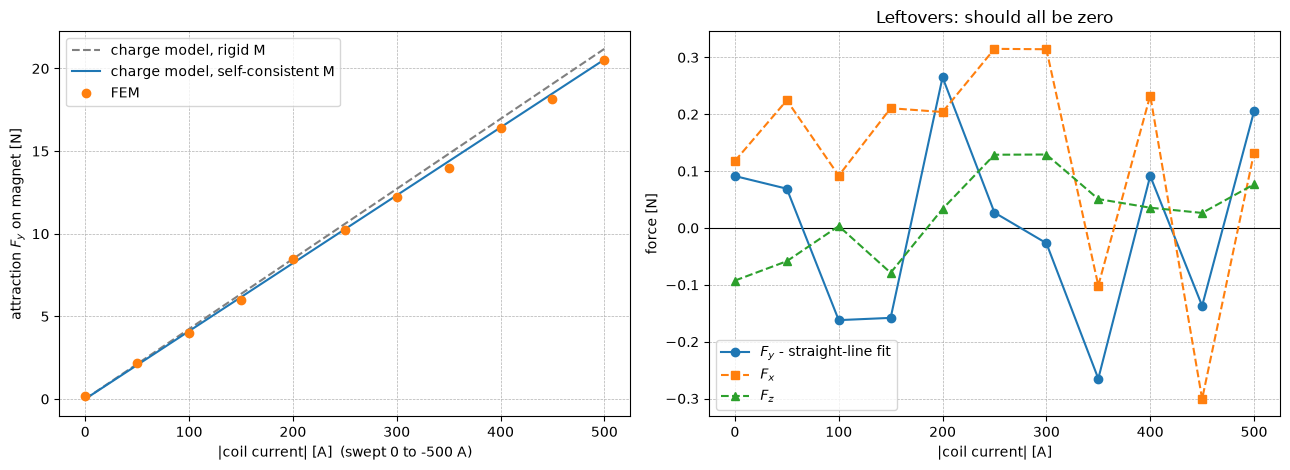

In [3]:
# 5. Force vs current, and what's left after the straight-line fit
I_line = np.linspace(0, I.min(), 50)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(-I_line, k_rigid * (-I_line), "--", color="gray", label="charge model, rigid M")
ax[0].plot(-I_line, k_sc * (-I_line), "-", label="charge model, self-consistent M")
ax[0].plot(-I, Fy, "o", label="FEM")
ax[0].set_xlabel("|coil current| [A]  (swept 0 to -500 A)")
ax[0].set_ylabel("attraction $F_y$ on magnet [N]")
ax[0].legend()
ax[0].grid(True, ls="--", lw=0.5)

ax[1].axhline(0, color="k", lw=0.8)
ax[1].plot(-I, resid, "o-", label="$F_y$ - straight-line fit")
ax[1].plot(-I, fem["Force_x_N"], "s--", label="$F_x$")
ax[1].plot(-I, fem["Force_z_N"], "^--", label="$F_z$")
ax[1].set_xlabel("|coil current| [A]")
ax[1].set_ylabel("force [N]")
ax[1].set_title("Leftovers: should all be zero")
ax[1].legend()
ax[1].grid(True, ls="--", lw=0.5)

plt.tight_layout()
plt.savefig("Images/Week6_ex5_force_vs_current_charge_model.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

The magnet is pulled toward the coil with a force that grows linearly with current, up to 20.5 N at −500 A. The FEM slope is 0.0404 N/A. The charge model gives 0.0424 N/A with a rigid $M$. With the block's own demagnetizing field taken into account ($N_\text{self} \approx 0.6$, $M$ about 3% lower), it gives 0.0411 N/A, which is 1.6% above the FEM. The force is linear in $M$ here, not quadratic as in the magnet-pair case, so the recoil correction only moves it by about 3%.

What's left is numerical, not physics. There is a 0.20 N force at zero current, where a lone magnet in air can feel nothing, and the points scatter by about ±0.16 N around the line. The side forces wander by up to 0.3 N with no trend. All of this is consistent with each point being a separate adaptive solve with the virtual-force method. It is small (about 1% of the largest force) and has no structure worth chasing, so no further runs are needed. The current sweep added to the original notebook gives the linear force-vs-current behavior an air-core coil should have.